
# CreditWise AI — Credit Risk Prediction System

**CodeAlpha Machine Learning Internship | Project 01**

## Project Overview
This project aims to develop and evaluate machine learning models for predicting credit risk using historical financial data.

We will explore the dataset, preprocess features, compare classification models, evaluate their performance, and build an interactive demonstration application.

**Dataset:** South German Credit — UCI Machine Learning Repository

**Tools:** Python, Pandas, Scikit-learn, Matplotlib, Seaborn, Streamlit

**Note:** This is an educational machine learning project, not a real-world credit approval system.

---

## 1. Dataset Loading and Initial Exploration


In [1]:

%pip install -q ucimlrepo


In [4]:

import pandas as pd
import requests
import zipfile
import io

# Official UCI South German Credit dataset
url = "https://archive.ics.uci.edu/static/public/522/south+german+credit.zip"

# Download the original dataset archive
response = requests.get(url, timeout=30)
response.raise_for_status()

# Read the dataset from the ZIP archive
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    with z.open("SouthGermanCredit.asc") as file:
        df = pd.read_csv(file, sep=r"\s+")

# Separate features and target
X = df.drop(columns=["kredit"])
y = df["kredit"]

# Check dataset dimensions
print("Dataset shape:", df.shape)
print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Preview the original records
display(df.head())


Dataset shape: (1000, 21)
Features shape: (1000, 20)
Target shape: (1000,)


,laufkont,laufzeit,moral,verw,hoehe,sparkont,beszeit,rate,famges,buerge,...,verm,alter,weitkred,wohn,bishkred,beruf,pers,telef,gastarb,kredit
0,1,18,4,2,1049,1,2,4,2,1,...,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,...,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,...,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,...,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,...,2,38,1,2,2,2,2,1,1,1



## 2. Understanding the Dataset

In this section, we examine the dataset's structure, data types, missing values, duplicate records, and target class distribution before preprocessing and model training.


In [5]:

# Display all column names
print("Column names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset information:")
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate records:", df.duplicated().sum())

# Examine target class distribution
print("\nCredit risk class distribution:")
print(df["kredit"].value_counts().sort_index())

print("\nClass percentages:")
print(
    df["kredit"].value_counts(
        normalize=True
    ).sort_index().mul(100).round(2)
)


Column names:
['laufkont', 'laufzeit', 'moral', 'verw', 'hoehe', 'sparkont', 'beszeit', 'rate', 'famges', 'buerge', 'wohnzeit', 'verm', 'alter', 'weitkred', 'wohn', 'bishkred', 'beruf', 'pers', 'telef', 'gastarb', 'kredit']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   laufkont  1000 non-null   int64
 1   laufzeit  1000 non-null   int64
 2   moral     1000 non-null   int64
 3   verw      1000 non-null   int64
 4   hoehe     1000 non-null   int64
 5   sparkont  1000 non-null   int64
 6   beszeit   1000 non-null   int64
 7   rate      1000 non-null   int64
 8   famges    1000 non-null   int64
 9   buerge    1000 non-null   int64
 10  wohnzeit  1000 non-null   int64
 11  verm      1000 non-null   int64
 12  alter     1000 non-null   int64
 13  weitkred  1000 non-null   int64
 14  wohn      1000 non-null   int64
 15  bishkred  1000


## 3. Exploratory Data Analysis (EDA)

We begin by examining the distribution of credit risk classes. Understanding this imbalance will help us choose appropriate evaluation metrics and modeling strategies.


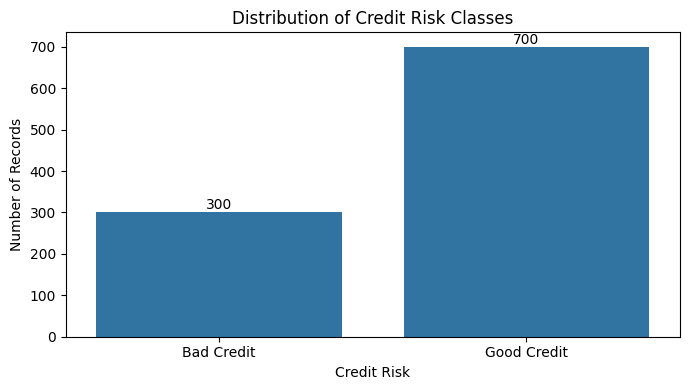

In [6]:

import matplotlib.pyplot as plt
import seaborn as sns

# Map original target values to readable labels
risk_labels = df["kredit"].map({
    0: "Bad Credit",
    1: "Good Credit"
})

# Visualize class distribution
plt.figure(figsize=(7, 4))

ax = sns.countplot(
    x=risk_labels,
    order=["Bad Credit", "Good Credit"]
)

plt.title("Distribution of Credit Risk Classes")
plt.xlabel("Credit Risk")
plt.ylabel("Number of Records")

# Add actual counts above bars
for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()



### Key Finding: Credit Risk Distribution

The dataset contains 700 good-credit records (70%) and 300 bad-credit records (30%), indicating an imbalanced target distribution.

Therefore, model performance will be evaluated using precision, recall, F1-score, and ROC-AUC rather than accuracy alone. Particular attention will be given to identifying bad-credit cases.



### Distribution of Numerical Features

We examine credit amount, loan duration, and applicant age to understand their distributions and identify potential skewness or unusual values.


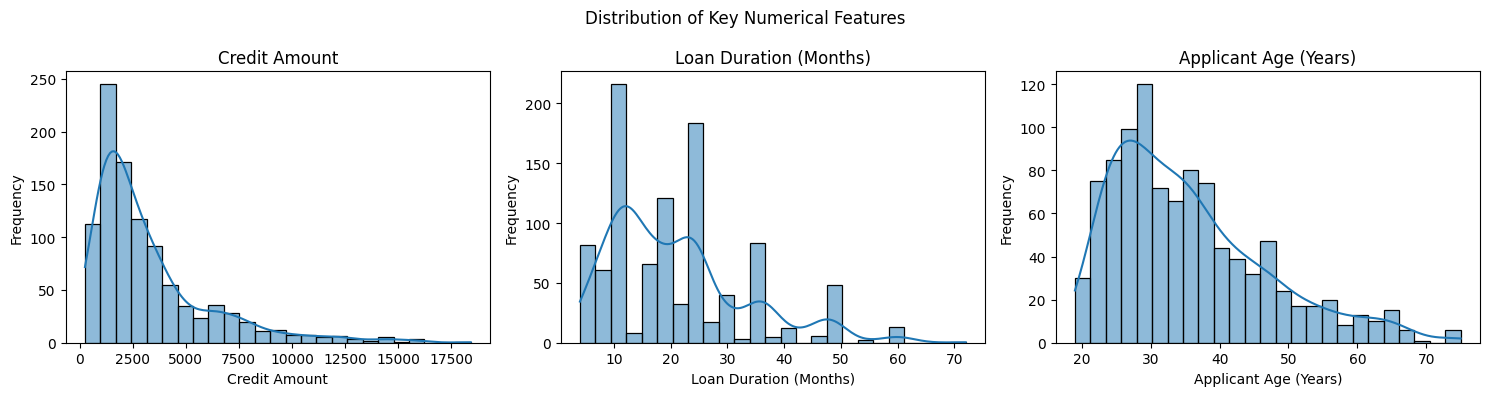

In [7]:

# Numerical feature distributions
features = {
    "hoehe": "Credit Amount",
    "laufzeit": "Loan Duration (Months)",
    "alter": "Applicant Age (Years)"
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (column, title) in zip(axes, features.items()):
    sns.histplot(
        data=df,
        x=column,
        bins=25,
        kde=True,
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel(title)
    ax.set_ylabel("Frequency")

plt.suptitle("Distribution of Key Numerical Features")
plt.tight_layout()
plt.show()



### Key Findings: Numerical Feature Distributions

- **Credit Amount:** The distribution is strongly right-skewed, with most loans concentrated at lower amounts and relatively few large loans.
- **Loan Duration:** Shorter loan durations are more frequent, with distinct peaks across several duration values.
- **Applicant Age:** The distribution is right-skewed, with fewer observations at older ages.

These patterns suggest that further statistical examination may be useful before preprocessing. We will also investigate how these features differ between credit risk classes.



### Numerical Features by Credit Risk

We compare the distributions of credit amount, loan duration, and applicant age between good-credit and bad-credit records to identify possible associations with credit risk.


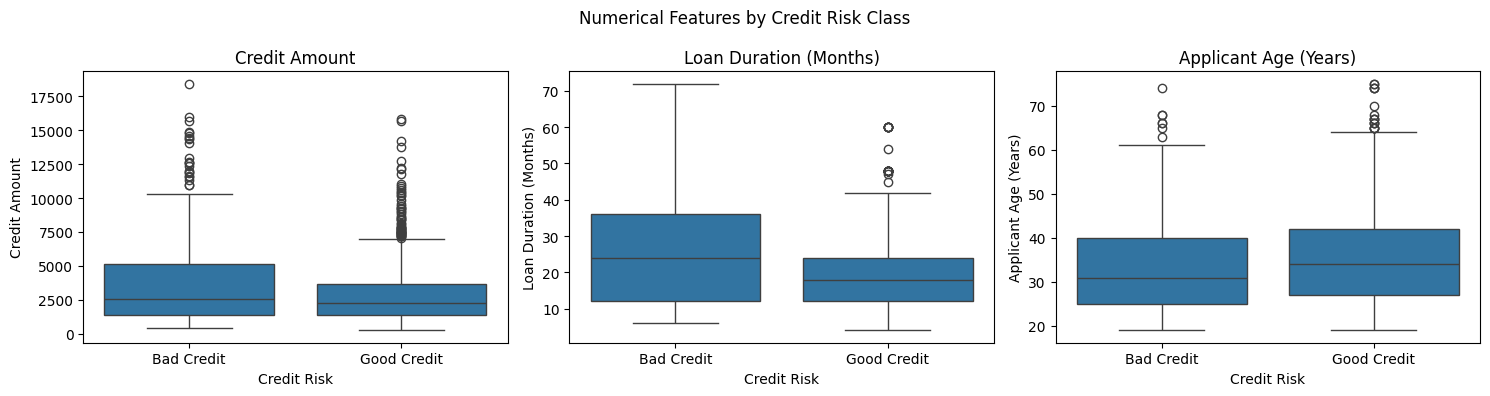

In [8]:

# Create readable credit risk labels
df["Credit_Risk"] = df["kredit"].map({
    0: "Bad Credit",
    1: "Good Credit"
})

# Compare numerical features by credit risk
features = {
    "hoehe": "Credit Amount",
    "laufzeit": "Loan Duration (Months)",
    "alter": "Applicant Age (Years)"
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (column, title) in zip(axes, features.items()):
    sns.boxplot(
        data=df,
        x="Credit_Risk",
        y=column,
        order=["Bad Credit", "Good Credit"],
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Credit Risk")
    ax.set_ylabel(title)

plt.suptitle("Numerical Features by Credit Risk Class")
plt.tight_layout()
plt.show()



### Key Findings: Numerical Features by Credit Risk

- **Credit Amount:** Bad-credit records generally have higher credit amounts and greater variability than good-credit records.
- **Loan Duration:** Bad-credit records tend to have longer loan durations, suggesting a possible association between repayment duration and credit risk.
- **Applicant Age:** Good-credit records show a slightly higher median age, although the distributions overlap considerably.

Both credit classes contain potential outliers. These observations are descriptive and do not establish causal relationships or model feature importance.



### Summary Statistics by Credit Risk

To complement the visual analysis, we calculate the count, mean, median, standard deviation, minimum, and maximum of key numerical features for each credit risk class.


In [9]:

# Calculate descriptive statistics by credit risk
summary_stats = (
    df.groupby("Credit_Risk")[
        ["hoehe", "laufzeit", "alter"]
    ]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

display(summary_stats)


hoehe                                       laufzeit         \
            count     mean  median      std  min    max    count   mean   
Credit_Risk                                                               
Bad Credit    300  3938.13  2574.5  3535.82  433  18424      300  24.86   
Good Credit   700  2985.44  2244.0  2401.50  250  15857      700  19.21   

                                  alter                               
            median    std min max count   mean median    std min max  
Credit_Risk                                                           
Bad Credit    24.0  13.28   6  72   300  33.96   31.0  11.23  19  74  
Good Credit   18.0  11.08   4  60   700  36.22   34.0  11.35  19  75


### Key Findings: Summary Statistics

- Bad-credit records have a higher mean credit amount (3,938.13) than good-credit records (2,985.44).
- The mean loan duration is longer for bad-credit records (24.86 months) than good-credit records (19.21 months).
- The median loan duration is 24 months for bad-credit records and 18 months for good-credit records.
- Credit amounts show considerable variability, with relatively large maximum values in both classes.

These findings support the patterns observed in the boxplots. However, they represent descriptive associations rather than causal relationships.



## 4. Categorical Feature Exploration

Several variables in the dataset represent categories encoded as integers. We examine their unique values and frequencies to understand the dataset structure before selecting appropriate preprocessing techniques.


In [10]:

# Examine unique values and frequencies
# Exclude the target and visualization label

categorical_candidates = [
    col for col in X.columns
    if col not in ["laufzeit", "hoehe", "alter"]
]

for col in categorical_candidates:
    print(f"\nFeature: {col}")
    print("Unique values:", sorted(df[col].unique()))
    print("Number of categories:", df[col].nunique())



Feature: laufkont
Unique values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Number of categories: 4

Feature: moral
Unique values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Number of categories: 5

Feature: verw
Unique values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(8), np.int64(9), np.int64(10)]
Number of categories: 10

Feature: sparkont
Unique values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Number of categories: 5

Feature: beszeit
Unique values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Number of categories: 5

Feature: rate
Unique values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Number of categories: 4

Feature: famges
Unique values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Number of categories: 4

Feature: buerge
Unique values: [np.int64(1), np.int64(2), np.int64(3)]
Number of categories: 3

Feature: wohnzeit
Uni


### Key Findings: Feature Types

The dataset contains 20 predictor variables:

- 3 quantitative features
- 10 categorical features
- 7 ordinal or discretized features

Although all variables are stored as integers, many represent category codes rather than continuous measurements.

Appropriate feature encoding will therefore be necessary before model training. Feature definitions were checked against the official UCI South German Credit documentation.


In [11]:

# Feature groups based on UCI dataset documentation

numerical_features = [
    "laufzeit", "hoehe", "alter"
]

categorical_features = [
    "laufkont", "moral", "verw", "sparkont",
    "famges", "buerge", "weitkred",
    "wohn", "telef", "gastarb"
]

ordinal_features = [
    "beszeit", "rate", "wohnzeit",
    "verm", "bishkred", "beruf", "pers"
]

# Verify that every predictor is assigned exactly once
all_features = (
    numerical_features
    + categorical_features
    + ordinal_features
)

assert len(all_features) == len(set(all_features))
assert set(all_features) == set(X.columns)

print("Feature grouping verified!")
print("Numerical:", len(numerical_features))
print("Categorical:", len(categorical_features))
print("Ordinal:", len(ordinal_features))
print("Total predictors:", len(all_features))


Feature grouping verified!
Numerical: 3
Categorical: 10
Ordinal: 7
Total predictors: 20



## 5. Data Preparation and Train-Test Split

The dataset is divided into training (80%) and testing (20%) subsets using stratified sampling.

We define bad credit as the positive class (1) so that evaluation metrics focus on identifying higher-risk cases.

The test set will be held out during model development. Preprocessing transformations will be fitted only on training data to prevent data leakage.


In [12]:

from sklearn.model_selection import train_test_split

# Use the original 20 predictors only
X = df[all_features].copy()

# Define bad credit as the positive class
# Original kredit: 0 = Bad, 1 = Good
y = 1 - df["kredit"]

# Split the data while preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

# Verify original predictors and split sizes
assert X_train.shape[1] == 20
assert len(X_train) + len(X_test) == len(df)
assert set(X_train.index).isdisjoint(set(X_test.index))

print("\nTrain-test split verified!")


Training samples: 800
Testing samples: 200

Training target distribution:
kredit
0    560
1    240
Name: count, dtype: int64

Testing target distribution:
kredit
0    140
1     60
Name: count, dtype: int64

Train-test split verified!



## 6. Data Preprocessing Pipeline

We create a reusable preprocessing pipeline to prepare numerical and categorical features for machine learning.

- Numerical features will be standardized.
- Categorical and discretized features will be one-hot encoded.
- Preprocessing will be fitted only on training data to prevent data leakage.

The pipeline will later be integrated with classification models for reproducible training and evaluation.


In [13]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine categorical and ordinal/discretized features
encoded_features = categorical_features + ordinal_features

# Combine transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, encoded_features)
    ]
)

# Check our configuration without fitting
print("Preprocessing pipeline created successfully!")
print("Numerical features:", len(numerical_features))
print("Encoded features:", len(encoded_features))
print("Total original features:",
      len(numerical_features) + len(encoded_features))

display(preprocessor)


Preprocessing pipeline created successfully!
Numerical features: 3
Encoded features: 17
Total original features: 20


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('scaler', StandardScaler())]),
                                 ['laufzeit', 'hoehe', 'alter']),
                                ('cat',
                                 Pipeline(steps=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['laufkont', 'moral', 'verw', 'sparkont',
                                  'famges', 'buerge', 'weitkred', 'wohn',
                                  'telef', 'gastarb', 'beszeit', 'rate',
                                  'wohnzeit', 'verm', 'bishkred', 'beruf',
                                  'pers'])])


## 7. Baseline Model Development

We compare a majority-class baseline with Logistic Regression to establish initial classification performance.

Both models are evaluated using stratified 5-fold cross-validation on the training data. Preprocessing is included inside the Logistic Regression pipeline to prevent data leakage.

We focus on identifying bad-credit records, which are represented by the positive class (1).

Model performance is assessed using accuracy, precision, recall, F1-score, and ROC-AUC.


In [14]:

import pandas as pd

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

# Reproducible cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Majority-class baseline
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

# Logistic Regression with preprocessing
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Models to compare
models = {
    "Majority Class Baseline": dummy_model,
    "Logistic Regression": logistic_model
}

# Evaluation metrics
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc"
}

results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    row = {"Model": name}

    for metric in scoring:
        row[metric] = scores[
            f"test_{metric}"
        ].mean()

    results.append(row)

# Display actual cross-validation results
results_df = pd.DataFrame(results)

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Majority Class Baseline,0.7000,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.7438,0.5954,0.4875,0.5326,0.7798



### Baseline Model Results

Logistic Regression outperformed the majority-class baseline across the evaluated metrics.

- Accuracy increased from 70.00% to 74.38%.
- Logistic Regression achieved an F1-score of 0.5326 and ROC-AUC of 0.7798.
- Recall for bad-credit cases was 0.4875, indicating that the model missed a substantial proportion of higher-risk records at the default threshold.

These results were obtained through stratified 5-fold cross-validation on the training set. Further model comparisons are required before final model selection.



### Random Forest Model Comparison

We evaluate Random Forest using the same stratified 5-fold cross-validation procedure and evaluation metrics as our baseline models.

The objective is to compare its predictive performance with Logistic Regression without accessing the held-out test set.


In [15]:

from sklearn.ensemble import RandomForestClassifier

# Random Forest model with preprocessing
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=1
    ))
])

# Evaluate using the same cross-validation procedure
rf_scores = cross_validate(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Store actual evaluation results
rf_result = {"Model": "Random Forest"}

for metric in scoring:
    rf_result[metric] = rf_scores[
        f"test_{metric}"
    ].mean()

# Compare all three models
comparison_df = pd.concat([
    results_df,
    pd.DataFrame([rf_result])
], ignore_index=True)

display(comparison_df.round(4))


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Majority Class Baseline,0.7000,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.7438,0.5954,0.4875,0.5326,0.7798
2,Random Forest,0.7425,0.6416,0.3458,0.4428,0.7831



### Model Comparison Findings

Three models were evaluated using stratified 5-fold cross-validation on the training dataset.

- Logistic Regression achieved the highest accuracy (0.7438), recall (0.4875), and F1-score (0.5326).
- Random Forest achieved higher precision (0.6416) and a slightly higher ROC-AUC (0.7831).
- Both models outperformed the majority-class baseline in identifying bad-credit cases.

Logistic Regression is currently the preferred candidate based on its better recall and F1-score. However, further validation and threshold analysis are required before final model selection.

The held-out test dataset has not been used.



## 8. Decision Threshold Analysis

We examine how different classification thresholds affect precision, recall, and F1-score.

Out-of-fold predictions from the training dataset are used to analyze threshold performance without accessing the held-out test set.


In [16]:

import numpy as np
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Generate out-of-fold probabilities on training data
oof_probabilities = cross_val_predict(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Compare a small set of decision thresholds
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60]

threshold_results = []

for threshold in thresholds:
    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Threshold,Precision,Recall,F1
0,0.2,0.4586,0.8083,0.5852
1,0.3,0.5169,0.7000,0.5947
2,0.4,0.5525,0.5917,0.5714
3,0.5,0.5879,0.4875,0.5330
4,0.6,0.6643,0.3958,0.4961



### Key Findings: Decision Threshold Analysis

The classification threshold substantially affects the balance between precision and recall.

- At threshold 0.50, recall was 0.4875 and F1-score was 0.5330.
- At threshold 0.30, recall increased to 0.7000 and F1-score improved to 0.5947.
- At threshold 0.20, recall increased further to 0.8083, but precision decreased to 0.4586.

Among the evaluated thresholds, 0.30 produced the highest observed F1-score. However, this result is exploratory and requires independent validation before final model selection.

The held-out test dataset remains unused.



## 9. Nested Cross-Validation for Threshold Selection

We evaluate a threshold-selection procedure using nested stratified cross-validation.

Within each outer training fold, an inner cross-validation procedure selects the threshold that maximizes F1-score. The selected threshold is then evaluated on the corresponding outer validation fold.

This provides a less optimistic assessment of the threshold-selection strategy while preserving the independent test set for final evaluation.


In [17]:

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score

# Inner and outer cross-validation
outer_cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

inner_cv = StratifiedKFold(
    n_splits=4, shuffle=True, random_state=24
)

candidate_thresholds = [0.20, 0.30, 0.40, 0.50, 0.60]

nested_results = []

for fold, (train_idx, val_idx) in enumerate(
    outer_cv.split(X_train, y_train), start=1
):
    X_inner_train = X_train.iloc[train_idx]
    y_inner_train = y_train.iloc[train_idx]

    X_outer_val = X_train.iloc[val_idx]
    y_outer_val = y_train.iloc[val_idx]

    # Inner out-of-fold probabilities
    inner_probs = cross_val_predict(
        clone(logistic_model),
        X_inner_train,
        y_inner_train,
        cv=inner_cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    # Select threshold using inner training data only
    threshold_scores = {
        t: f1_score(
            y_inner_train,
            (inner_probs >= t).astype(int)
        )
        for t in candidate_thresholds
    }

    best_threshold = max(
        threshold_scores,
        key=threshold_scores.get
    )

    # Fit model on outer training fold
    model = clone(logistic_model)
    model.fit(X_inner_train, y_inner_train)

    # Evaluate on unseen outer validation fold
    outer_probs = model.predict_proba(X_outer_val)[:, 1]
    outer_predictions = (
        outer_probs >= best_threshold
    ).astype(int)

    nested_results.append({
        "Fold": fold,
        "Threshold": best_threshold,
        "Precision": precision_score(
            y_outer_val, outer_predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_outer_val, outer_predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_outer_val, outer_predictions,
            zero_division=0
        )
    })

nested_df = pd.DataFrame(nested_results)

display(nested_df.round(4))

print("\nMean performance across outer folds:")
display(
    nested_df[["Precision", "Recall", "F1"]]
    .mean()
    .round(4)
)


,Fold,Threshold,Precision,Recall,F1
0,1,0.2,0.4805,0.7708,0.5920
1,2,0.3,0.5781,0.7708,0.6607
2,3,0.2,0.4270,0.7917,0.5547
3,4,0.3,0.4833,0.6042,0.5370
4,5,0.3,0.5000,0.7708,0.6066



Mean performance across outer folds:


,0
Precision,0.4938
Recall,0.7417
F1,0.5902



### Nested Cross-Validation Findings

Nested stratified cross-validation was used to evaluate the Logistic Regression threshold-selection procedure.

- Selected thresholds ranged from 0.20 to 0.30 across the five outer folds.
- Mean precision was 0.4938.
- Mean recall was 0.7417.
- Mean F1-score was 0.5902.

These results suggest that lower decision thresholds can improve identification of bad-credit cases compared with the default threshold of 0.50.

Threshold selection was performed within the inner folds, while performance was evaluated on separate outer validation folds. The independent test set remains untouched.



## 10. Final Training-Set Threshold Selection

Following nested cross-validation, the final decision threshold is selected using out-of-fold predictions from the complete training dataset.

The threshold maximizing F1-score among the predefined candidates is selected. This threshold will remain fixed during independent test evaluation.


In [18]:

from sklearn.metrics import f1_score

# Candidate thresholds evaluated previously
candidate_thresholds = [0.20, 0.30, 0.40, 0.50, 0.60]

# Use the previously generated out-of-fold probabilities
final_threshold_scores = {}

for threshold in candidate_thresholds:
    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    final_threshold_scores[threshold] = f1_score(
        y_train,
        predictions
    )

# Select highest F1 threshold
selected_threshold = max(
    final_threshold_scores,
    key=final_threshold_scores.get
)

print("Selected threshold:", selected_threshold)
print(
    "Training OOF F1 at selected threshold:",
    round(final_threshold_scores[selected_threshold], 4)
)

# Display all candidate scores
display(
    pd.DataFrame({
        "Threshold": list(final_threshold_scores.keys()),
        "OOF_F1": list(final_threshold_scores.values())
    }).round(4)
)


Selected threshold: 0.3
Training OOF F1 at selected threshold: 0.5947


,Threshold,OOF_F1
0,0.2,0.5852
1,0.3,0.5947
2,0.4,0.5714
3,0.5,0.5330
4,0.6,0.4961



### Final Threshold Selection

A decision threshold of 0.30 was selected using training-set out-of-fold predictions.

This threshold achieved the highest observed F1-score (0.5947) among the predefined candidates.

Nested cross-validation was used earlier to evaluate the threshold-selection procedure, obtaining a mean outer-fold F1-score of 0.5902.

The selected threshold is now fixed for independent evaluation on the held-out test set.



## 11. Final Model Training and Independent Evaluation

The selected Logistic Regression pipeline is trained using the complete training dataset.

The fixed decision threshold of 0.30 is applied to the held-out test set. Performance is measured using accuracy, precision, recall, F1-score, ROC-AUC, and the confusion matrix.

The test data were not used during model development or threshold selection.


Independent Test Set Results
Decision threshold: 0.3


,Metric,Score
0,Accuracy,0.6850
1,Precision,0.4805
2,Recall,0.6167
3,F1,0.5401
4,ROC-AUC,0.7418


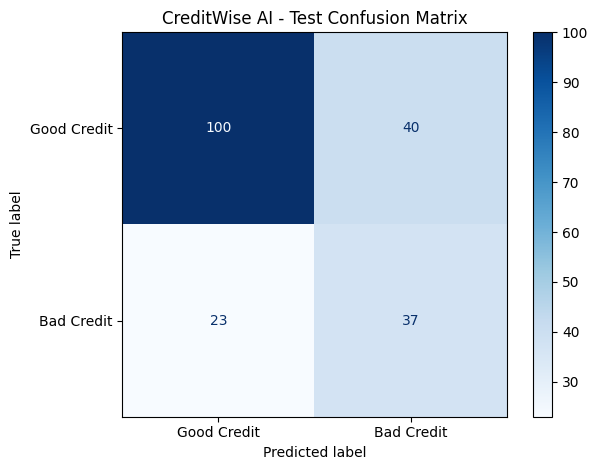

In [19]:

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

# Train the selected model on all training records
final_model = clone(logistic_model)
final_model.fit(X_train, y_train)

# Obtain probabilities for bad credit (class 1)
test_probabilities = final_model.predict_proba(X_test)[:, 1]

# Apply the previously selected threshold
test_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

# Calculate independent test metrics
test_metrics = {
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_test, test_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities)
}

print("Independent Test Set Results")
print("Decision threshold:", selected_threshold)

display(
    pd.DataFrame(
        test_metrics.items(),
        columns=["Metric", "Score"]
    ).round(4)
)

# Display confusion matrix
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Good Credit", "Bad Credit"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("CreditWise AI - Test Confusion Matrix")
plt.tight_layout()
plt.show()



### Independent Test Evaluation Findings

The Logistic Regression model was evaluated on 200 held-out records using the predefined decision threshold of 0.30.

**Test performance:**
- Accuracy: 0.6850
- Precision: 0.4805
- Recall: 0.6167
- F1-score: 0.5401
- ROC-AUC: 0.7418

The confusion matrix showed 100 true negatives, 40 false positives, 23 false negatives, and 37 true positives, where bad credit represents the positive class.

The model correctly identified 37 of 60 bad-credit records but missed 23. It also incorrectly flagged 40 good-credit records.

Test performance was lower than the nested cross-validation estimates, indicating limitations in generalization.

These results are specific to the historical dataset and do not establish suitability for real-world credit decisions.



## 12. Model Interpretation

We examine the fitted Logistic Regression coefficients to understand how individual encoded features are associated with the model's predicted log-odds of bad credit.

Coefficient values are interpreted as model associations, not causal effects.


In [20]:

# Retrieve fitted preprocessing and classifier
fitted_preprocessor = final_model.named_steps["preprocessor"]
fitted_classifier = final_model.named_steps["classifier"]

# Get transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = fitted_classifier.coef_[0]

# Create a coefficient table
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by absolute coefficient magnitude
coef_df["Absolute_Coefficient"] = (
    coef_df["Coefficient"].abs()
)

coef_df = coef_df.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

display(coef_df.head(15).round(4))


,Feature,Coefficient,Absolute_Coefficient
13,cat__verw_1,-1.0516,1.0516
6,cat__laufkont_4,-0.9438,0.9438
11,cat__moral_4,-0.9151,0.9151
8,cat__moral_1,0.9029,0.9029
3,cat__laufkont_1,0.7812,0.7812
12,cat__verw_0,0.7569,0.7569
22,cat__sparkont_1,0.6968,0.6968
25,cat__sparkont_4,-0.6883,0.6883
43,cat__gastarb_2,0.6210,0.6210
42,cat__gastarb_1,-0.6203,0.6203



### Key Findings: Logistic Regression Coefficients

The largest absolute coefficients include encoded categories associated with loan purpose, checking-account status, credit history, and savings-account status.

Positive coefficients correspond to higher predicted log-odds of bad credit, while negative coefficients correspond to lower predicted log-odds.

These coefficients describe associations within the fitted model, not causal relationships.

Because categorical variables were one-hot encoded, coefficient magnitudes should not be interpreted as definitive rankings of original feature importance.

The model also contains demographic attributes that require careful consideration of fairness and potential bias.



### Visualization of Logistic Regression Coefficients

The following visualization displays the 15 encoded features with the largest absolute coefficients.

The direction of each coefficient indicates its association with the predicted log-odds of bad credit, while magnitude represents the strength of the coefficient in the fitted model.


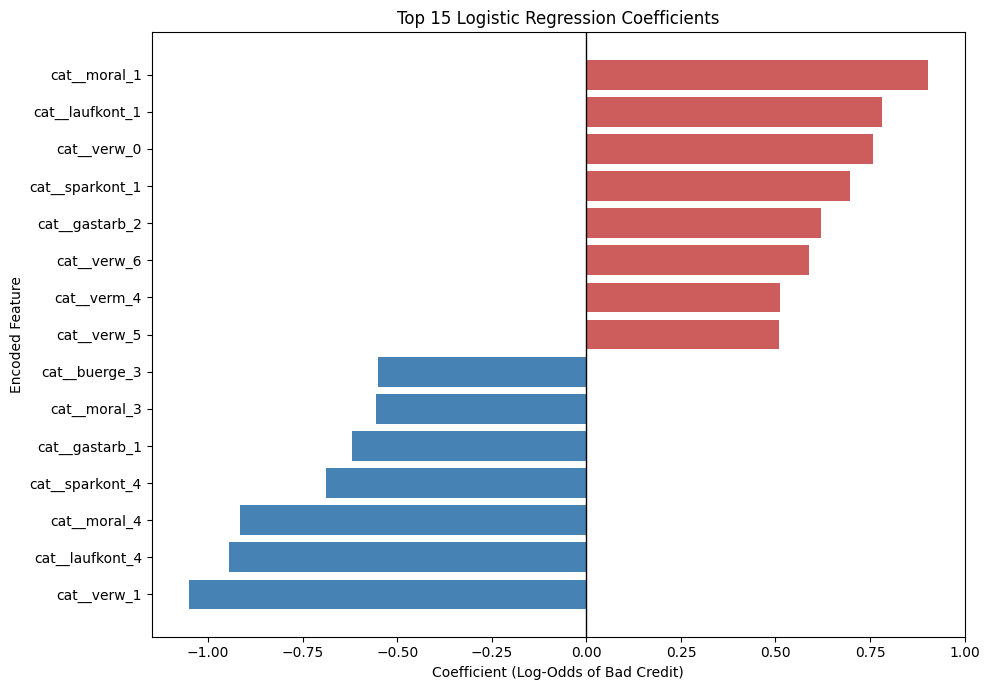

In [21]:

# Select the 15 largest absolute coefficients
top_coefficients = coef_df.head(15).copy()

# Sort for horizontal plotting
top_coefficients = top_coefficients.sort_values(
    "Coefficient"
)

# Plot positive and negative coefficients
plt.figure(figsize=(10, 7))

colors = [
    "steelblue" if value < 0 else "indianred"
    for value in top_coefficients["Coefficient"]
]

plt.barh(
    top_coefficients["Feature"],
    top_coefficients["Coefficient"],
    color=colors
)

plt.axvline(0, color="black", linewidth=1)

plt.title("Top 15 Logistic Regression Coefficients")
plt.xlabel("Coefficient (Log-Odds of Bad Credit)")
plt.ylabel("Encoded Feature")

plt.tight_layout()
plt.show()



### Coefficient Visualization Findings

The visualization highlights encoded categories associated with higher and lower predicted log-odds of bad credit.

Large coefficients are observed for categories related to credit history, checking-account status, loan purpose, and savings-account status.

These results help describe the fitted model's behavior but do not establish causal relationships or definitive feature-importance rankings.

The presence of demographic attributes also highlights the need to consider potential bias and fairness limitations.



## 13. Model Export and Reproducibility

The fitted Logistic Regression pipeline and its selected decision threshold are saved together for use in the CreditWise AI application.

The export includes the expected input feature names so that future predictions use the same feature structure as model training.

The saved model is then reloaded and checked for prediction consistency.


In [22]:

import joblib
import numpy as np
import sklearn
from pathlib import Path

# Package the trained model and required metadata
model_artifact = {
    "model": final_model,
    "threshold": float(selected_threshold),
    "feature_names": X_train.columns.tolist(),
    "positive_class": 1,
    "dataset": "UCI South German Credit",
    "sklearn_version": sklearn.__version__
}

# Save artifact
model_path = Path("creditwise_model.joblib")

joblib.dump(model_artifact, model_path)

print("Model saved:", model_path)
print("Scikit-learn version:", sklearn.__version__)

# Reload saved artifact
loaded_artifact = joblib.load(model_path)

# Compare original and reloaded probabilities
original_probs = final_model.predict_proba(X_test)[:, 1]

reloaded_probs = loaded_artifact[
    "model"
].predict_proba(
    X_test[loaded_artifact["feature_names"]]
)[:, 1]

# Verify identical probability outputs
np.testing.assert_allclose(
    original_probs,
    reloaded_probs,
    rtol=1e-10,
    atol=1e-12
)

# Verify threshold
assert loaded_artifact["threshold"] == selected_threshold

print("Model reload verification passed!")


Model saved: creditwise_model.joblib
Scikit-learn version: 1.6.1
Model reload verification passed!
